# EN4554 Assignment 2 on CNNs

**Name:** Lakshan K.P.

**Index Number:** 220353F

**GitHub Repository:** to be attached

**Acknowledgement:** I used Claude (Anthropic) to help with coding. I reviewed and understood all the code in this notebook.

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


**Fixing Random Seeds**

In [3]:
import random

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

- Random seeds are fixed for Python, NumPy, and PyTorch.
- This makes the data split, weight initialization, and shuffling the same in every run.
- So the results can be repeated.

**Train / Validation Split and Normalization**

In [4]:
# Load the CIFAR-10 training set (raw images)
raw_train = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
classes = raw_train.classes

# Split 50k training images into 45k train and 5k validation
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(raw_train), generator=g)
train_idx = perm[:45000].tolist()
val_idx = perm[45000:].tolist()

# Per-channel mean and std from the 45k training images only
train_data = raw_train.data[train_idx]
mean, std = [], []
for c in range(3):
    channel = train_data[:, :, :, c].astype(np.float32) / 255.0
    mean.append(float(channel.mean()))
    std.append(float(channel.std()))

print("Train size:", len(train_idx))
print("Validation size:", len(val_idx))
print("Mean (R, G, B):", np.round(mean, 4))
print("Std  (R, G, B):", np.round(std, 4))

100%|██████████| 170M/170M [27:09<00:00, 105kB/s]


Train size: 45000
Validation size: 5000
Mean (R, G, B): [0.4917 0.4823 0.4467]
Std  (R, G, B): [0.2471 0.2435 0.2616]


- CIFAR-10 has 50k training images and 10k test images, with 10 classes of 32×32 RGB images.
- The 50k training images are split randomly into 45k train and 5k validation.
- Hyperparameters are chosen using the validation set.
- The mean and std of each channel (R, G, B) are computed from the 45k training images only.
- Validation and test images are not used here. This avoids leaking information from them.
- Each image is normalized as (x − mean) / std. This gives each channel about zero mean and unit variance, which helps training.

**Data Loaders and Data Check**

In [5]:
normalize = transforms.Normalize(mean, std)
base_transform = transforms.Compose([transforms.ToTensor(), normalize])

full_train = torchvision.datasets.CIFAR10(root="./data", train=True, download=True,
                                          transform=base_transform)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True,
                                        transform=base_transform)

train_set = Subset(full_train, train_idx)
val_set = Subset(full_train, val_idx)

def get_loaders(train_ds=train_set, val_ds=val_set, batch_size=128):
    g = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=2, generator=g)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2)
    return train_loader, val_loader

train_loader, val_loader = get_loaders()

# Check normalization on one batch
x, y = next(iter(train_loader))
print("Batch shape:", x.shape)
print("Batch mean per channel:", x.mean(dim=(0, 2, 3)).numpy().round(3))
print("Batch std per channel:", x.std(dim=(0, 2, 3)).numpy().round(3))

Batch shape: torch.Size([128, 3, 32, 32])
Batch mean per channel: [ 0.002 -0.031 -0.023]
Batch std per channel: [0.992 0.977 0.96 ]


- Each batch has shape (128, 3, 32, 32): batch size, channels, height, and width.
- After normalization, the batch mean of each channel is close to 0 and the std is close to 1.
- This shows the normalization works as expected.

# Task 1: Backpropagation

### (a) Linear, ReLU, and Softmax Cross-Entropy Layers with Manual Forward/Backward

In [6]:
class Linear:
    def __init__(self, in_features, out_features, dtype=torch.float32):
        std = np.sqrt(2.0 / in_features)    # He (Kaiming) initialization
        self.W = torch.randn(in_features, out_features, dtype=dtype, device=device) * std
        self.b = torch.zeros(out_features, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x                          # cache input for backward
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout           # dL/dW
        self.db = dout.sum(dim=0)           # dL/db
        return dout @ self.W.T              # dL/dx


class ReLU:
    def forward(self, x):
        self.mask = (x > 0)                 # cache where input is positive
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask             # pass gradient only where x > 0


class SoftmaxCrossEntropy:
    def forward(self, scores, y):
        N = scores.shape[0]
        shifted = scores - scores.max(dim=1, keepdim=True).values   # numerical stability
        exp_s = torch.exp(shifted)
        sum_exp = exp_s.sum(dim=1, keepdim=True)
        self.probs = exp_s / sum_exp
        self.y = y
        log_probs = shifted - torch.log(sum_exp)
        return -log_probs[torch.arange(N), y].mean()

    def backward(self):
        N = self.probs.shape[0]
        dscores = self.probs.clone()
        dscores[torch.arange(N), self.y] -= 1   # p - one_hot(y)
        return dscores / N


class MLP:
    def __init__(self, sizes, activation=ReLU, dtype=torch.float32):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], dtype))
            if i < len(sizes) - 2:              # no activation after last layer
                self.layers.append(activation())

    def forward(self, x):
        x = x.reshape(x.shape[0], -1)           # flatten images
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, dout):
        for layer in reversed(self.layers):
            dout = layer.backward(dout)
        return dout

    def linear_layers(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def params(self):
        p = []
        for l in self.linear_layers():
            p += [l.W, l.b]
        return p

    def grads(self):
        g = []
        for l in self.linear_layers():
            g += [l.dW, l.db]
        return g

**Layer Equations**

Each layer saves what it needs in the forward pass. The backward pass uses the chain rule:
downstream gradient = local gradient × upstream gradient.

**Linear layer:** $y = xW + b$, where $x$ is $N \times D$ and $W$ is $D \times M$.
- $\dfrac{\partial L}{\partial W} = x^T \dfrac{\partial L}{\partial y}$
- $\dfrac{\partial L}{\partial b} = \sum_{n} \dfrac{\partial L}{\partial y_n}$ (sum over the batch)
- $\dfrac{\partial L}{\partial x} = \dfrac{\partial L}{\partial y} W^T$

**ReLU:** $y = \max(0, x)$
- $\dfrac{\partial L}{\partial x} = \dfrac{\partial L}{\partial y}$ where $x > 0$, and $0$ elsewhere.

**Softmax cross-entropy:**
- $p_k = \dfrac{e^{s_k}}{\sum_j e^{s_j}}$, and $L = -\dfrac{1}{N}\sum_i \log p_{y_i}$
- $\dfrac{\partial L}{\partial s} = \dfrac{1}{N}\left(p - \text{onehot}(y)\right)$, where $\text{onehot}(y)$ is a vector with 1 at the correct class and 0 elsewhere.
- The maximum score is subtracted before taking the exponent. This prevents overflow and does not change the result.

**MLP:**
- Layers are stacked as Linear → ReLU → … → Linear.
- The forward pass goes from first to last layer. The backward pass goes in reverse order.
- Weights use He initialization, with std $= \sqrt{2 / D_{in}}$. Biases start at zero.

In [7]:
set_seed(SEED)
model = MLP([3072, 256, 128, 10])
loss_fn = SoftmaxCrossEntropy()

x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)

scores = model.forward(x)
loss = loss_fn.forward(scores, y)
dx = model.backward(loss_fn.backward())

print("Scores shape:", scores.shape)
print("Initial loss:", round(loss.item(), 4), "| Expected ≈ log(10) =", round(np.log(10), 4))
for i, l in enumerate(model.linear_layers()):
    print(f"Layer {i+1}: W {tuple(l.W.shape)}, dW {tuple(l.dW.shape)}, db {tuple(l.db.shape)}")

Scores shape: torch.Size([128, 10])
Initial loss: 3.2186 | Expected ≈ log(10) = 2.3026
Layer 1: W (3072, 256), dW (3072, 256), db (256,)
Layer 2: W (256, 128), dW (256, 128), db (128,)
Layer 3: W (128, 10), dW (128, 10), db (10,)


**Check of the MLP**

- The output scores have shape (128, 10): one score for each of the 10 classes, for each image in the batch.
- Each gradient (dW, db) has the same shape as its parameter (W, b). This is required for the update step.
- The initial loss is 3.22. If the model predicted all classes equally, the loss would be log(10) = 2.30.
- The loss is higher than 2.30 because He initialization gives scores that are not close to zero. So the softmax output is not uniform, and some wrong classes get high probability.
- The loss is still in a reasonable range, which shows the forward pass works correctly.

### (b) Gradient Check: Autograd and Centred Finite Differences

**Setup for the check**
- A small network and float64 are used, so rounding errors do not hide real mistakes.
- The relative error is $\dfrac{|g_{manual} - g_{ref}|}{|g_{manual}| + |g_{ref}|}$. The largest value is reported.

In [8]:
import pandas as pd

def rel_error(a, b):
    # max of |a - b| / (|a| + |b|), with a small floor to avoid division by zero
    return (torch.abs(a - b) / torch.clamp(torch.abs(a) + torch.abs(b), min=1e-12)).max().item()

set_seed(SEED)
check_model = MLP([3072, 64, 32, 10], dtype=torch.float64)
loss_fn = SoftmaxCrossEntropy()

xb = torch.stack([train_set[i][0] for i in range(16)]).to(device, torch.float64)
yb = torch.tensor([train_set[i][1] for i in range(16)], device=device)

**Manual gradients**
- The gradients are computed with our own forward and backward passes, without autograd.

In [9]:
manual_loss = loss_fn.forward(check_model.forward(xb), yb)
check_model.backward(loss_fn.backward())
manual_grads = check_model.grads()

**Autograd gradients**
- The same weights are copied into tensors with `requires_grad=True`.
- The same network is run with PyTorch operations and `F.cross_entropy`.
- `loss.backward()` gives the reference gradients.

In [10]:
def autograd_grads(model, x, y):
    params = [p.clone().requires_grad_(True) for p in model.params()]
    h = x.reshape(x.shape[0], -1)
    n = len(params) // 2
    for i in range(n):
        h = h @ params[2 * i] + params[2 * i + 1]
        if i < n - 1:
            h = torch.relu(h)
    loss = F.cross_entropy(h, y)
    loss.backward()
    return loss, [p.grad for p in params]

auto_loss, auto_grads = autograd_grads(check_model, xb, yb)

**Centred finite differences**
- For one weight $w$, the gradient is estimated as
  $\dfrac{\partial L}{\partial w} \approx \dfrac{L(w + h) - L(w - h)}{2h}$, with $h = 10^{-5}$.
- This needs two forward passes per weight, so only 20 random entries of each parameter are checked.

In [11]:
def finite_diff(model, x, y, n_checks=20, h=1e-5):
    g = torch.Generator().manual_seed(SEED)
    num_list, idx_list = [], []
    for p in model.params():
        flat = p.view(-1)
        idx = torch.randint(0, flat.numel(), (n_checks,), generator=g)
        nums = []
        for i in idx:
            old = flat[i].item()
            flat[i] = old + h
            loss_plus = loss_fn.forward(model.forward(x), y).item()
            flat[i] = old - h
            loss_minus = loss_fn.forward(model.forward(x), y).item()
            flat[i] = old                                  # restore
            nums.append((loss_plus - loss_minus) / (2 * h))
        num_list.append(torch.tensor(nums, dtype=torch.float64, device=p.device))
        idx_list.append(idx.to(p.device))
    return num_list, idx_list

num_grads, num_idx = finite_diff(check_model, xb, yb)

**Results**
- `torch.allclose` checks whether all entries match within the given tolerance.

In [12]:
names = ["W1", "b1", "W2", "b2", "W3", "b3"]
rows = []
for name, m, a, n, idx in zip(names, manual_grads, auto_grads, num_grads, num_idx):
    m_sub = m.reshape(-1)[idx]
    rows.append({
        "Param": name,
        "Shape": tuple(m.shape),
        "Rel. error vs autograd": f"{rel_error(m, a):.2e}",
        "allclose (autograd)": torch.allclose(m, a, rtol=1e-5, atol=1e-8),
        "Rel. error vs finite diff": f"{rel_error(m_sub, n):.2e}",
        "allclose (finite diff)": torch.allclose(m_sub, n, rtol=1e-5, atol=1e-7),
    })

print(f"Manual loss: {manual_loss.item():.8f} | Autograd loss: {auto_loss.item():.8f}")
pd.DataFrame(rows)

Manual loss: 2.96787217 | Autograd loss: 2.96787217


,Param,Shape,Rel. error vs autograd,allclose (autograd),Rel. error vs finite diff,allclose (finite diff)
0,W1,"(3072, 64)",2.37e-11,True,1.28e-08,True
1,b1,"(64,)",1.82e-14,True,3.35e-09,True
2,W2,"(64, 32)",5.35e-14,True,8.69e-08,True
3,b2,"(32,)",1.94e-16,True,2.51e-10,True
4,W3,"(32, 10)",3.82e-16,True,6.10e-09,True
5,b3,"(10,)",1.05e-16,True,3.41e-10,True


**Interpretation**

- The manual loss and the autograd loss are the same (2.96787217). So the softmax cross-entropy forward pass is correct.
- Manual vs autograd:All relative errors are between $10^{-16}$ and $10^{-11}$. These are at the level of float64 rounding error. `torch.allclose` is True for every parameter.
- W1 has the largest error ($2.4 \times 10^{-11}$). It has the most entries (196,608), and the worst case is reported. Some entries are very close to zero, which makes the relative error larger. It is still very small.
- Manual vs finite differences: The relative errors are between $10^{-10}$ and $10^{-7}$. These are larger than the autograd errors because finite differences are only an approximation. They have a small error from the step size $h$ and from rounding.
- An error below about $10^{-7}$ is a good result for a gradient check. `torch.allclose` is True for every parameter.
- Both checks agree, so the manual backward pass for Linear, ReLU, and softmax cross-entropy is correct.

### (c) Training the MLP with SGD on Flattened CIFAR-10 Images

In [14]:
def evaluate(model, loader):
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        scores = model.forward(x)
        loss = loss_fn.forward(scores, y)
        total_loss += loss.item() * x.shape[0]
        correct += (scores.argmax(dim=1) == y).sum().item()
        n += x.shape[0]
    return total_loss / n, correct / n


def train_mlp_sgd(model, train_loader, val_loader, lr=0.01, epochs=20):
    history = {"iter_loss": [], "train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        total_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            # forward
            scores = model.forward(x)
            loss = loss_fn.forward(scores, y)

            # backward (manual)
            model.backward(loss_fn.backward())

            # SGD update: w = w - lr * dw
            for p, g in zip(model.params(), model.grads()):
                p -= lr * g

            history["iter_loss"].append(loss.item())
            total_loss += loss.item() * x.shape[0]
            correct += (scores.argmax(dim=1) == y).sum().item()
            n += x.shape[0]

        val_loss, val_acc = evaluate(model, val_loader)
        history["train_loss"].append(total_loss / n)
        history["train_acc"].append(correct / n)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch+1:2d} | train loss {total_loss/n:.4f} | train acc {correct/n:.4f} "
              f"| val loss {val_loss:.4f} | val acc {val_acc:.4f}")
    return history

**Training Setup**

- Network: MLP with layers 3072 → 256 → 128 → 10, with ReLU between the layers.
- Each 32×32×3 image is flattened into a vector of 3072 values.
- Loss: our softmax cross-entropy.
- Optimizer: mini-batch SGD, $w \leftarrow w - \eta \, \dfrac{\partial L}{\partial w}$, with learning rate $\eta = 0.01$ and batch size 128.
- The gradients come from our manual backward pass. No autograd is used.
- The model is trained for 20 epochs. After each epoch, the loss and accuracy are measured on the validation set.

In [15]:
set_seed(SEED)
mlp = MLP([3072, 256, 128, 10])
loss_fn = SoftmaxCrossEntropy()
train_loader, val_loader = get_loaders(batch_size=128)

start = time.time()
hist_mlp = train_mlp_sgd(mlp, train_loader, val_loader, lr=0.01, epochs=20)
print(f"Training time: {time.time() - start:.1f} s")
print(f"Final validation accuracy: {hist_mlp['val_acc'][-1]:.4f}")
print(f"Best validation accuracy: {max(hist_mlp['val_acc']):.4f} "
      f"(epoch {int(np.argmax(hist_mlp['val_acc'])) + 1})")

Epoch  1 | train loss 1.8499 | train acc 0.3486 | val loss 1.6932 | val acc 0.4044
Epoch  2 | train loss 1.5966 | train acc 0.4399 | val loss 1.6056 | val acc 0.4402
Epoch  3 | train loss 1.4935 | train acc 0.4813 | val loss 1.5672 | val acc 0.4482
Epoch  4 | train loss 1.4245 | train acc 0.5075 | val loss 1.5212 | val acc 0.4680
Epoch  5 | train loss 1.3668 | train acc 0.5276 | val loss 1.4966 | val acc 0.4754
Epoch  6 | train loss 1.3166 | train acc 0.5458 | val loss 1.4763 | val acc 0.4814
Epoch  7 | train loss 1.2714 | train acc 0.5645 | val loss 1.4708 | val acc 0.4890
Epoch  8 | train loss 1.2332 | train acc 0.5767 | val loss 1.4582 | val acc 0.4896
Epoch  9 | train loss 1.1951 | train acc 0.5909 | val loss 1.4603 | val acc 0.4910
Epoch 10 | train loss 1.1623 | train acc 0.6032 | val loss 1.4406 | val acc 0.4970
Epoch 11 | train loss 1.1285 | train acc 0.6160 | val loss 1.4339 | val acc 0.5020
Epoch 12 | train loss 1.0974 | train acc 0.6278 | val loss 1.4716 | val acc 0.4862
Epoc

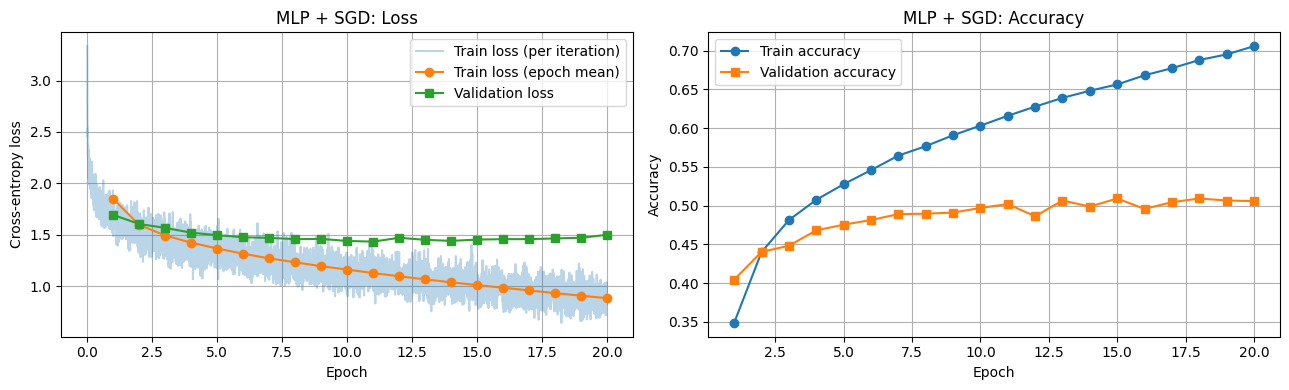

In [16]:
epochs = range(1, len(hist_mlp["train_loss"]) + 1)
iters_per_epoch = len(hist_mlp["iter_loss"]) / len(hist_mlp["train_loss"])
iter_x = np.arange(1, len(hist_mlp["iter_loss"]) + 1) / iters_per_epoch

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(iter_x, hist_mlp["iter_loss"], alpha=0.3, label="Train loss (per iteration)")
ax[0].plot(epochs, hist_mlp["train_loss"], "o-", label="Train loss (epoch mean)")
ax[0].plot(epochs, hist_mlp["val_loss"], "s-", label="Validation loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Cross-entropy loss")
ax[0].set_title("MLP + SGD: Loss")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(epochs, hist_mlp["train_acc"], "o-", label="Train accuracy")
ax[1].plot(epochs, hist_mlp["val_acc"], "s-", label="Validation accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].set_title("MLP + SGD: Accuracy")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

**Interpretation**

- **Validation accuracy:** The final validation accuracy is 50.6%, and the best is 50.9% (epoch 15). This is much better than random guessing (10%), so the manual MLP and SGD are learning.
- **Training loss:** It falls steadily from 1.85 to 0.88. The per-iteration loss is noisy because each mini-batch has only 128 images. The epoch mean is smooth.
- **Validation loss:** It is lowest at epoch 11 (1.43). After that it slowly rises to 1.50, while the training loss keeps falling.
- **Overfitting:** The train accuracy reaches 70.6%, but the validation accuracy stays near 50% after about epoch 10. The gap grows to about 20%. The model starts to memorize the training images instead of learning general features.
- **Why accuracy is limited:** Flattening the image removes its spatial structure. The MLP cannot use the fact that nearby pixels are related.
- Regularization or early stopping (around epoch 10–15) could reduce the overfitting.

### (d) Per-Layer Gradient Norm at Initialization: Sigmoid vs ReLU

In [17]:
class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))      # cache output for backward
        return self.out

    def backward(self, dout):
        return dout * self.out * (1.0 - self.out)   # dσ/dx = σ(1 - σ)


# 10-layer MLP: 10 Linear layers
sizes = [3072] + [256] * 9 + [10]

# One fixed batch of training images
gen = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(train_set), generator=gen)[:256].tolist()
xg = torch.stack([train_set[i][0] for i in idx]).to(device)
yg = torch.tensor([train_set[i][1] for i in idx], device=device)

def layer_grad_norms(activation):
    set_seed(SEED)                                  # same initial weights for both
    model = MLP(sizes, activation=activation)
    loss = loss_fn.forward(model.forward(xg), yg)
    model.backward(loss_fn.backward())
    norms = [l.dW.norm().item() for l in model.linear_layers()]
    return norms, loss.item()

loss_fn = SoftmaxCrossEntropy()
norms_sig, loss_sig = layer_grad_norms(Sigmoid)
norms_relu, loss_relu = layer_grad_norms(ReLU)

print(f"Initial loss | Sigmoid: {loss_sig:.4f} | ReLU: {loss_relu:.4f}")
pd.DataFrame({
    "Layer": range(1, 11),
    "||dW|| Sigmoid": [f"{v:.2e}" for v in norms_sig],
    "||dW|| ReLU": [f"{v:.2e}" for v in norms_relu],
})

Initial loss | Sigmoid: 2.4536 | ReLU: 2.6955


,Layer,||dW|| Sigmoid,||dW|| ReLU
0,1,1.81e-04,3.69e+00
1,2,1.40e-04,1.22e+00
2,3,4.24e-04,1.49e+00
3,4,1.28e-03,1.51e+00
4,5,4.00e-03,1.83e+00
5,6,1.21e-02,1.94e+00
6,7,3.98e-02,2.20e+00
7,8,1.27e-01,2.73e+00
8,9,4.27e-01,2.97e+00
9,10,1.26e+00,2.95e+00


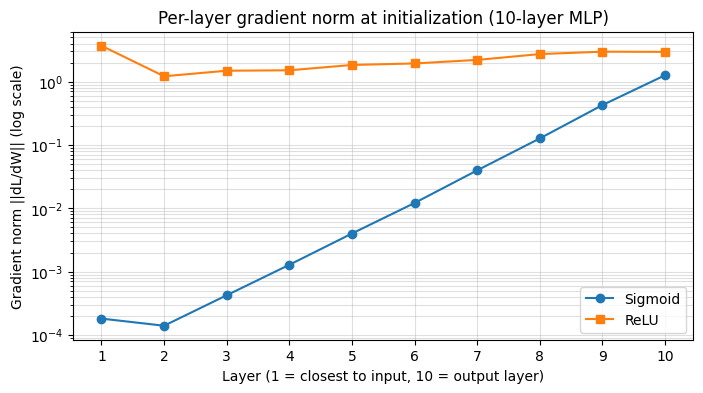

In [18]:
layers = range(1, 11)
plt.figure(figsize=(8, 4))
plt.semilogy(layers, norms_sig, "o-", label="Sigmoid")
plt.semilogy(layers, norms_relu, "s-", label="ReLU")
plt.xlabel("Layer (1 = closest to input, 10 = output layer)")
plt.ylabel("Gradient norm ||dL/dW|| (log scale)")
plt.title("Per-layer gradient norm at initialization (10-layer MLP)")
plt.xticks(list(layers))
plt.legend()
plt.grid(True, which="both", alpha=0.4)
plt.show()

**Setup**

- Both networks have 10 Linear layers: 3072 → 256 → … → 256 → 10.
- They use the same initial weights (He initialization, same seed) and the same batch of 256 images. Only the activation function is different.
- One forward and one backward pass are run with no training. Then the Frobenius norm $\|\partial L / \partial W\|$ of each layer is computed.
- Sigmoid: $\sigma(x) = \dfrac{1}{1 + e^{-x}}$, with local gradient $\sigma(x)(1 - \sigma(x)) \le 0.25$.
- ReLU: local gradient is 1 for $x > 0$ and 0 otherwise.
- The y-axis uses a log scale because the norms can differ by many orders of magnitude.

**Explanation**

**Sigmoid: vanishing gradients**
- The gradient norm is 1.26 at the output layer (layer 10) but only about $1.8 \times 10^{-4}$ at layer 1. This is about 7,000 times smaller.
- On the log plot, the norm falls in a nearly straight line. It shrinks by about 3 times at each layer going back.
- The reason is the chain rule. In the backward pass, the gradient is multiplied by the sigmoid's local gradient $\sigma(x)(1 - \sigma(x))$ at every layer.
- This local gradient is at most 0.25. After many layers, these small factors multiply together, and the gradient becomes very small.
- So the early layers get almost no gradient. They would learn very slowly. This is the vanishing gradient problem.

**ReLU: gradients stay stable**
- The gradient norm stays between about 1.2 and 3.7 in all layers. There is no large decay.
- ReLU's local gradient is exactly 1 for positive inputs. So the gradient passes back without shrinking through the active units.
- He initialization is designed for ReLU. It keeps the signal size about the same from layer to layer.

**Layer 1**
- Layer 1 has a slightly larger norm than layer 2 in both networks.
- The reason is that $\partial L / \partial W_1 = x^T \, \partial L / \partial y$ uses the 3072 input pixels, so it has many more entries than the other layers.

**Conclusion**
- ReLU allows all layers of a deep network to learn at similar speeds. A sigmoid network trains its early layers very slowly.
- This is why ReLU is preferred in deep networks.

# Task 2: Optimizers

### (a) SGD with Momentum and Adam as `torch.optim.Optimizer` Subclasses

In [20]:
class MySGDMomentum(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        defaults = dict(lr=lr, momentum=momentum)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, rho = group["lr"], group["momentum"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if "velocity" not in state:
                    state["velocity"] = torch.zeros_like(p)
                v = state["velocity"]
                v.mul_(rho).add_(p.grad)            # v = rho * v + dw
                p.add_(v, alpha=-lr)                # w = w - lr * v


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        defaults = dict(lr=lr, betas=betas, eps=eps)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, eps = group["lr"], group["eps"]
            beta1, beta2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                state = self.state[p]
                if len(state) == 0:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)     # first moment
                    state["v"] = torch.zeros_like(p)     # second moment
                state["t"] += 1
                t, m, v = state["t"], state["m"], state["v"]

                m.mul_(beta1).add_(g, alpha=1 - beta1)          # m = b1*m + (1-b1)*dw
                v.mul_(beta2).add_(g * g, alpha=1 - beta2)      # v = b2*v + (1-b2)*dw^2

                m_hat = m / (1 - beta1 ** t)                    # bias correction
                v_hat = v / (1 - beta2 ** t)

                p.add_(-lr * m_hat / (v_hat.sqrt() + eps))      # w = w - lr * m_hat / (sqrt(v_hat) + eps)

**Update Rules**

**SGD with momentum** (momentum $\rho$, learning rate $\eta$):
- $v_{t+1} = \rho \, v_t + \nabla_w L$
- $w_{t+1} = w_t - \eta \, v_{t+1}$
- The velocity $v$ is a running sum of past gradients. It keeps the update moving in a consistent direction.
- With $\rho = 0$, this becomes plain SGD.

**Adam** ($\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$):
- First moment (like momentum): $m_t = \beta_1 m_{t-1} + (1 - \beta_1) \nabla_w L$
- Second moment (squared gradients): $v_t = \beta_2 v_{t-1} + (1 - \beta_2) (\nabla_w L)^2$
- Bias correction: $\hat{m}_t = \dfrac{m_t}{1 - \beta_1^t}$, $\hat{v}_t = \dfrac{v_t}{1 - \beta_2^t}$
- Update: $w_t = w_{t-1} - \eta \, \dfrac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$
- $m$ and $v$ start at zero, so they are too small in the first steps. Bias correction fixes this.
- Dividing by $\sqrt{\hat{v}_t}$ gives each weight its own step size.

Both classes inherit from `torch.optim.Optimizer`. They store the velocity, or $m$, $v$, and $t$, in `self.state` for each parameter. They work with `zero_grad()` and autograd, like the built-in optimizers.

In [21]:
import copy

# Fixed list of training batches (float64 for an exact comparison)
set_seed(SEED)
cmp_loader, _ = get_loaders(batch_size=64)
cmp_batches = []
for i, (x, y) in enumerate(cmp_loader):
    if i == 50:
        break
    cmp_batches.append((x.to(device, torch.float64), y.to(device)))

def make_net():
    return nn.Sequential(nn.Flatten(), nn.Linear(3072, 64), nn.ReLU(),
                         nn.Linear(64, 10)).to(device, torch.float64)

def compare_optimizers(name, my_opt_fn, torch_opt_fn):
    set_seed(SEED)
    base = make_net()
    net_a, net_b = copy.deepcopy(base), copy.deepcopy(base)   # same starting weights
    opt_a, opt_b = my_opt_fn(net_a.parameters()), torch_opt_fn(net_b.parameters())

    for x, y in cmp_batches:
        for net, opt in [(net_a, opt_a), (net_b, opt_b)]:
            opt.zero_grad()
            loss = F.cross_entropy(net(x), y)
            loss.backward()
            opt.step()

    with torch.no_grad():
        loss_a = F.cross_entropy(net_a(cmp_batches[-1][0]), cmp_batches[-1][1]).item()
        loss_b = F.cross_entropy(net_b(cmp_batches[-1][0]), cmp_batches[-1][1]).item()
    pa, pb = list(net_a.parameters()), list(net_b.parameters())
    max_diff = max((a - b).abs().max().item() for a, b in zip(pa, pb))
    match = all(torch.allclose(a, b) for a, b in zip(pa, pb))
    return {"Optimizer": name, "Steps": len(cmp_batches),
            "Final loss (mine)": f"{loss_a:.8f}", "Final loss (torch)": f"{loss_b:.8f}",
            "Max |param diff|": f"{max_diff:.2e}", "allclose": match}

results = [
    compare_optimizers("SGD (momentum = 0)",
                       lambda p: MySGDMomentum(p, lr=0.01, momentum=0.0),
                       lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.0)),
    compare_optimizers("SGD + momentum (0.9)",
                       lambda p: MySGDMomentum(p, lr=0.01, momentum=0.9),
                       lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9)),
    compare_optimizers("Adam",
                       lambda p: MyAdam(p, lr=1e-3),
                       lambda p: torch.optim.Adam(p, lr=1e-3)),
]
pd.DataFrame(results)

,Optimizer,Steps,Final loss (mine),Final loss (torch),Max |param diff|,allclose
0,SGD (momentum = 0),50,2.04183572,2.04183572,0.00e+00,True
1,SGD + momentum (0.9),50,1.98366748,1.98366748,0.00e+00,True
2,Adam,50,2.02128785,2.02128785,2.78e-17,True


**Comparison Method**

- Two copies of the same small network start with identical weights.
- One copy is trained with our optimizer, and the other with the PyTorch optimizer.
- Both use the same 50 mini-batches, in the same order, with the same hyperparameters.
- Float64 is used so small rounding differences do not hide real mistakes.
- After training, all parameters are compared with `torch.allclose`. The largest absolute difference is also reported.

**Interpretation**

- For all three optimizers, our final loss is the same as PyTorch's to 8 decimal places. `torch.allclose` is True for all parameters.
- SGD and SGD with momentum: The parameter difference is exactly 0. Our update does the same operations in the same order as `torch.optim.SGD`, so the results are identical.
- Adam: The largest difference is $2.8 \times 10^{-17}$, which is at the level of float64 rounding error. PyTorch arranges the bias-corrected update in a slightly different order. This causes tiny rounding differences, but the maths is the same.
- So both optimizers, including Adam's bias correction, are implemented correctly.
- After 50 steps, SGD with momentum reaches a lower loss (1.98) than plain SGD (2.04) at the same learning rate. Momentum adds up past gradients, which gives larger, steadier steps.

### (b) Optimizer Trajectories on $f(x, y) = \frac{1}{2}(x^2 + 50y^2)$

In [22]:
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def run_trajectory(opt_fn, start=(-10.0, 1.0), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_fn([p])
    path, losses = [p.detach().clone().numpy()], [f_quad(p).item()]
    for _ in range(steps):
        opt.zero_grad()
        loss = f_quad(p)
        loss.backward()
        opt.step()
        path.append(p.detach().clone().numpy())
        losses.append(f_quad(p).item())
    return np.array(path), np.array(losses)

lr_sgd, lr_adam = 0.035, 0.3
trajs = {
    f"SGD (lr={lr_sgd})": run_trajectory(lambda ps: MySGDMomentum(ps, lr=lr_sgd, momentum=0.0)),
    f"SGD + momentum (lr={lr_sgd}, ρ=0.9)": run_trajectory(lambda ps: MySGDMomentum(ps, lr=lr_sgd, momentum=0.9)),
    f"Adam (lr={lr_adam})": run_trajectory(lambda ps: MyAdam(ps, lr=lr_adam)),
}

pd.DataFrame({
    "Optimizer": list(trajs.keys()),
    "f after 10 steps": [f"{l[10]:.3e}" for _, l in trajs.values()],
    "f after 50 steps": [f"{l[50]:.3e}" for _, l in trajs.values()],
    "f after 100 steps": [f"{l[100]:.3e}" for _, l in trajs.values()],
    "Final (x, y)": [f"({p[-1,0]:.3f}, {p[-1,1]:.3f})" for p, _ in trajs.values()],
})

,Optimizer,f after 10 steps,f after 50 steps,f after 100 steps,"Final (x, y)"
0,SGD (lr=0.035),2.460e+01,1.418e+00,4.022e-02,"(-0.284, 0.000)"
1,"SGD + momentum (lr=0.035, ρ=0.9)",1.543e+01,4.582e-01,1.452e-03,"(-0.045, 0.004)"
2,Adam (lr=0.3),2.792e+01,7.310e-02,1.384e-03,"(-0.051, -0.002)"


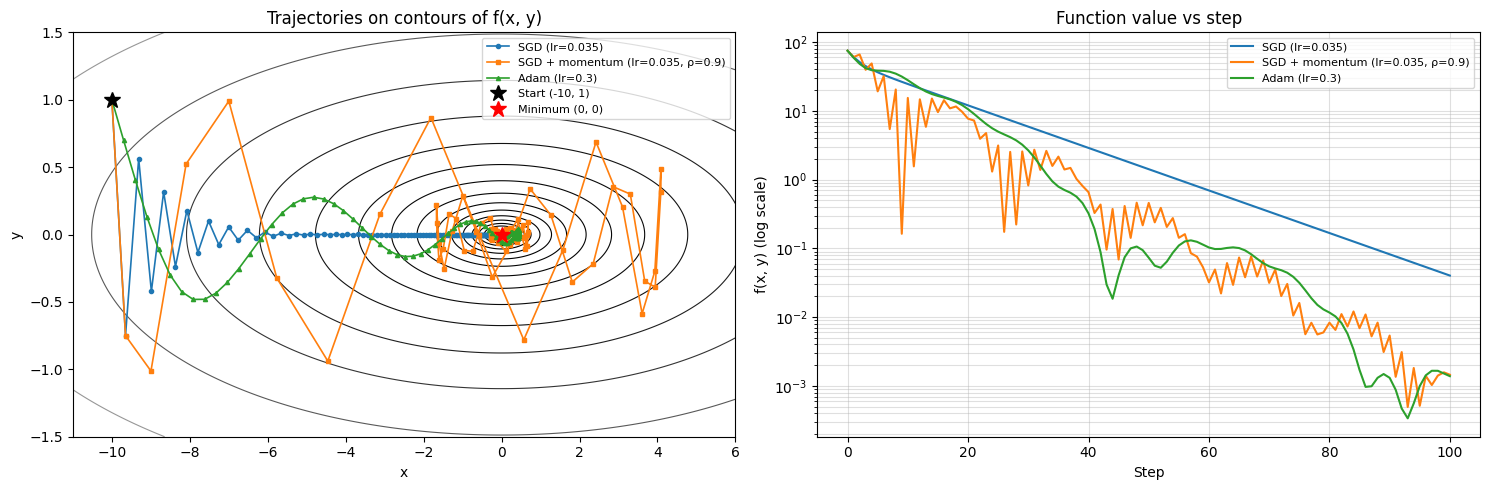

In [24]:
xs = np.linspace(-11, 6, 400)
ys = np.linspace(-1.5, 1.5, 400)
X, Y = np.meshgrid(xs, ys)
Z = 0.5 * (X ** 2 + 50 * Y ** 2)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].contour(X, Y, Z, levels=np.logspace(-1, 2.2, 15), cmap="gray", linewidths=0.8)
markers = ["o", "s", "^"]
for (name, (path, _)), mk in zip(trajs.items(), markers):
    ax[0].plot(path[:, 0], path[:, 1], marker=mk, markersize=3, linewidth=1.2, label=name)
ax[0].plot(-10, 1, "k*", markersize=12, label="Start (-10, 1)")
ax[0].plot(0, 0, "r*", markersize=12, label="Minimum (0, 0)")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].set_title("Trajectories on contours of f(x, y)")
ax[0].legend(fontsize=8)

for (name, (_, losses)), mk in zip(trajs.items(), markers):
    ax[1].semilogy(losses, label=name)
ax[1].set_xlabel("Step")
ax[1].set_ylabel("f(x, y) (log scale)")
ax[1].set_title("Function value vs step")
ax[1].legend(fontsize=8)
ax[1].grid(True, which="both", alpha=0.4)

plt.tight_layout()
plt.show()

**Setup**

- The gradient is $\nabla f = (x, \; 50y)$. The function is 50 times steeper in $y$ than in $x$.
- So the contours are long, thin ellipses. This is a function with a high condition number.
- All optimizers start at $(-10, 1)$ and run for 100 steps. The minimum is at $(0, 0)$.
- Our own optimizer classes from part (a) are used.
- SGD and SGD with momentum use $\eta = 0.035$. Plain SGD is unstable in $y$ if $\eta > 2/50 = 0.04$, so the learning rate must stay below this limit.
- Adam uses $\eta = 0.3$ with $\beta_1 = 0.9$ and $\beta_2 = 0.999$.

**Explanation of the Differences**

The function is 50 times steeper in $y$ than in $x$. So a good step size for $y$ is too small for $x$. This is the high condition number problem.

**SGD**
- In the first steps, the path zig-zags across the narrow valley in $y$. Each step multiplies $y$ by $(1 - 50\eta) = -0.75$. So $y$ changes sign every step, but it slowly shrinks.
- Along the shallow $x$ direction, each step multiplies $x$ by only $(1 - \eta) = 0.965$. So SGD moves very slowly toward the minimum.
- On the log plot, $f$ falls as a straight line, but slowly. After 100 steps, $f = 4.0 \times 10^{-2}$, and $x$ is still $-0.28$.
- The learning rate cannot be increased to speed up $x$. Above $\eta = 0.04$, the $y$ direction becomes unstable.

**SGD with momentum**
- The velocity adds up gradients that point in the same direction. Along $x$, the gradient sign stays the same, so the speed builds up. The path moves much faster in $x$.
- But momentum also causes overshoot. The path passes the minimum, reaches about $x = 4$, and swings widely in $y$ (up to ±1). Then it turns back.
- So $f$ goes up and down from step to step. But overall it falls much faster than SGD: $f = 1.5 \times 10^{-3}$ after 100 steps, about 28 times lower than SGD.

**Adam**
- Adam divides each gradient by $\sqrt{\hat{v}}$, its running size. So both $x$ and $y$ take steps of similar size, even though $y$ is 50 times steeper.
- The path is smooth and curved. There is no sharp zig-zag in $y$. The small waves around the $x$-axis come from the momentum part ($\beta_1$).
- Adam reaches the lowest value early: $f = 7.3 \times 10^{-2}$ after 50 steps, compared with 0.46 for momentum and 1.42 for SGD.
- After 100 steps, it ends at $f = 1.4 \times 10^{-3}$, similar to momentum.

**Summary**
- SGD makes slow progress along the shallow direction and jitters along the steep direction.
- Momentum speeds up the shallow direction but overshoots.
- Adam gives each direction its own step size, so it follows the valley more directly and smoothly.

### (c) Small CNN Trained with SGD, SGD + Momentum, and Adam at Three Learning Rates

In [25]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32 x 16 x 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 64 x 8 x 8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 128 x 4 x 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def evaluate_net(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += F.cross_entropy(out, y).item() * x.shape[0]
            correct += (out.argmax(dim=1) == y).sum().item()
            n += x.shape[0]
    return total_loss / n, correct / n


def train_net(model, opt, train_loader, val_loader, epochs=10, verbose=False):
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        total_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = F.cross_entropy(out, y)
            loss.backward()
            opt.step()
            total_loss += loss.item() * x.shape[0]
            correct += (out.argmax(dim=1) == y).sum().item()
            n += x.shape[0]
        val_loss, val_acc = evaluate_net(model, val_loader)
        hist["train_loss"].append(total_loss / n)
        hist["train_acc"].append(correct / n)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        if verbose:
            print(f"  Epoch {epoch+1:2d} | train loss {total_loss/n:.4f} | val acc {val_acc:.4f}")
    return hist


n_params = sum(p.numel() for p in SmallCNN().parameters())
print("SmallCNN parameters:", n_params)

SmallCNN parameters: 356810


**Network and Training Setup**

- Small CNN: three blocks of Conv 3×3 → ReLU → MaxPool 2×2, with 32, 64, and 128 channels. Then a fully connected layer with 128 units and an output layer with 10 classes.
- Padding of 1 keeps the size the same after each convolution. Each max pool halves the size: 32 → 16 → 8 → 4.
- Optimizers: our own classes from part (a):
  - Plain SGD (momentum = 0)
  - SGD with momentum ($\rho = 0.9$)
  - Adam ($\beta_1 = 0.9$, $\beta_2 = 0.999$)
- Learning rates: the same three values for every optimizer: $10^{-1}$, $10^{-2}$, and $10^{-3}$. This lets us compare how each optimizer reacts to the same change in learning rate.
- Each run starts from the same initial weights (same seed). It uses batch size 128 and 10 epochs.
- For each run, the best validation accuracy over the 10 epochs is reported.

In [26]:
opt_builders = {
    "SGD": lambda p, lr: MySGDMomentum(p, lr=lr, momentum=0.0),
    "SGD + momentum": lambda p, lr: MySGDMomentum(p, lr=lr, momentum=0.9),
    "Adam": lambda p, lr: MyAdam(p, lr=lr),
}
lrs = [1e-1, 1e-2, 1e-3]
EPOCHS_OPT = 10

opt_results = {}
start = time.time()
for name, build in opt_builders.items():
    for lr in lrs:
        set_seed(SEED)
        model = SmallCNN().to(device)
        opt = build(model.parameters(), lr)
        train_loader, val_loader = get_loaders(batch_size=128)
        hist = train_net(model, opt, train_loader, val_loader, epochs=EPOCHS_OPT)
        opt_results[(name, lr)] = hist
        print(f"{name:15s} lr={lr:<6} | best val acc {max(hist['val_acc']):.4f} "
              f"| final train loss {hist['train_loss'][-1]:.4f}")
print(f"Total time: {(time.time() - start) / 60:.1f} min")

SGD             lr=0.1    | best val acc 0.7396 | final train loss 0.4252
SGD             lr=0.01   | best val acc 0.5306 | final train loss 1.2454
SGD             lr=0.001  | best val acc 0.2326 | final train loss 2.2068
SGD + momentum  lr=0.1    | best val acc 0.5972 | final train loss 1.1649
SGD + momentum  lr=0.01   | best val acc 0.7594 | final train loss 0.3680
SGD + momentum  lr=0.001  | best val acc 0.5668 | final train loss 1.2169
Adam            lr=0.1    | best val acc 0.1064 | final train loss 2.3082
Adam            lr=0.01   | best val acc 0.5536 | final train loss 1.1675
Adam            lr=0.001  | best val acc 0.7606 | final train loss 0.2970
Total time: 17.4 min


In [27]:
rows = []
for (name, lr), h in opt_results.items():
    rows.append({"Optimizer": name, "Learning rate": lr,
                 "Best val acc": round(max(h["val_acc"]), 4),
                 "Final val acc": round(h["val_acc"][-1], 4),
                 "Final train loss": round(h["train_loss"][-1], 4)})
opt_table = pd.DataFrame(rows)
opt_table

,Optimizer,Learning rate,Best val acc,Final val acc,Final train loss
0,SGD,0.100,0.7396,0.6856,0.4252
1,SGD,0.010,0.5306,0.5306,1.2454
2,SGD,0.001,0.2326,0.2326,2.2068
3,SGD + momentum,0.100,0.5972,0.5722,1.1649
4,SGD + momentum,0.010,0.7594,0.7572,0.3680
5,SGD + momentum,0.001,0.5668,0.5668,1.2169
6,Adam,0.100,0.1064,0.0976,2.3082
7,Adam,0.010,0.5536,0.5536,1.1675
8,Adam,0.001,0.7606,0.7560,0.2970


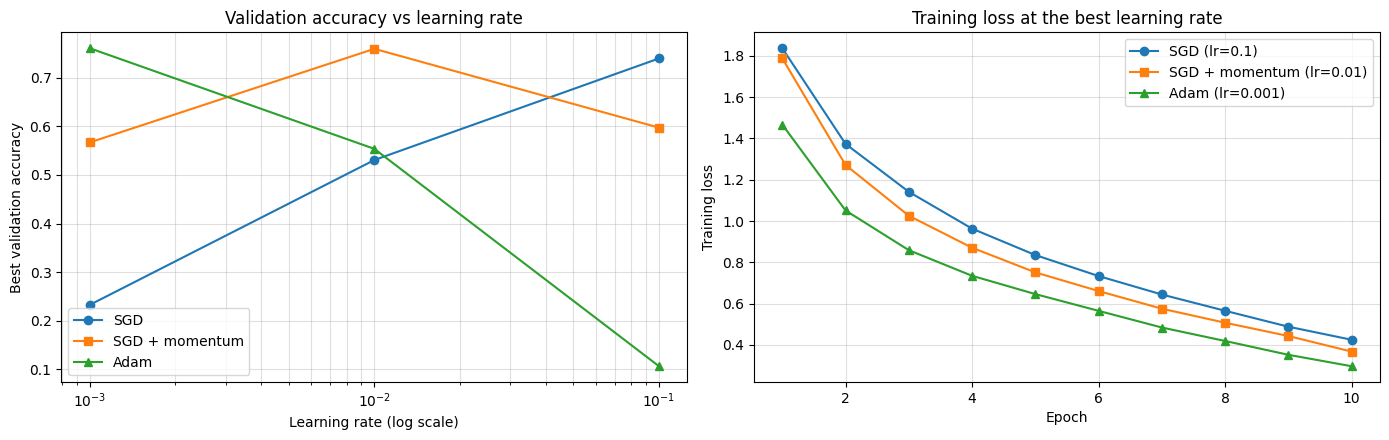

Best learning rates: {'SGD': 0.1, 'SGD + momentum': 0.01, 'Adam': 0.001}


In [28]:
best_lr = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

for name, mk in zip(opt_builders, ["o", "s", "^"]):
    accs = [max(opt_results[(name, lr)]["val_acc"]) for lr in lrs]
    best_lr[name] = lrs[int(np.argmax(accs))]
    ax[0].semilogx(lrs, accs, marker=mk, label=name)
ax[0].set_xlabel("Learning rate (log scale)")
ax[0].set_ylabel("Best validation accuracy")
ax[0].set_title("Validation accuracy vs learning rate")
ax[0].legend()
ax[0].grid(True, which="both", alpha=0.4)

ep = range(1, EPOCHS_OPT + 1)
for name, mk in zip(opt_builders, ["o", "s", "^"]):
    lr = best_lr[name]
    ax[1].plot(ep, opt_results[(name, lr)]["train_loss"], marker=mk, label=f"{name} (lr={lr})")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Training loss")
ax[1].set_title("Training loss at the best learning rate")
ax[1].legend()
ax[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()
print("Best learning rates:", best_lr)

**Discussion: Learning Rate Sensitivity**

**Best results** (small CNN with 356,810 parameters, 10 epochs)

| Optimizer | Best learning rate | Best val accuracy |
|---|---|---|
| SGD | 0.1 | 74.0% |
| SGD + momentum | 0.01 | 75.9% |
| Adam | 0.001 | 76.1% |

- At their best learning rates, all three optimizers reach similar accuracy (74–76%). Choosing the right learning rate matters more than choosing the optimizer.
- Each optimizer has a **different best learning rate**. So the learning rate must be tuned separately for each optimizer.

**Plain SGD**
- At lr = 0.001, it learns very slowly. After 10 epochs, the training loss is still 2.21, close to the starting value (log 10 = 2.30). Validation accuracy is only 23%.
- It needs a large learning rate (0.1) to train well in 10 epochs.
- At lr = 0.1, the final accuracy (68.6%) is lower than the best (74.0%). Large steps make the training less stable.

**SGD with momentum**
- The best learning rate is 10 times smaller than for SGD. With $\rho = 0.9$, the velocity adds up past gradients. So the effective step is about $\eta / (1 - \rho) = 10\eta$. Momentum at lr = 0.01 acts like SGD at lr = 0.1.
- At lr = 0.1, the effective step is too large. The accuracy drops to 59.7%.
- Accuracy ranges from 57% to 76% over the three learning rates. In this test, momentum is the **least sensitive** optimizer.

**Adam**
- The best learning rate is 0.001. This matches the usual recommended starting value for Adam.
- At lr = 0.1, Adam **fails completely**. The validation accuracy is 10.6%, which is random guessing. The training loss stays at 2.31 ≈ log 10.
- Adam scales each weight's step to roughly the size of the learning rate. With lr = 0.1, every weight moves by about 0.1 per step, which is far too large, and the network breaks.
- Accuracy ranges from 11% to 76%, so Adam is the **most sensitive** to a learning rate that is too high.

**Training loss at the best learning rate**
- Adam reduces the training loss fastest, especially in the first epochs. It ends lowest (0.30), followed by momentum (0.37) and SGD (0.43).
- All three curves are still going down at epoch 10. More epochs would likely improve all of them.

**Summary**
- A learning rate that is too small makes training very slow. A learning rate that is too large makes training unstable, or it fails completely.
- Only three learning rates were tested, 10 times apart. The true best value for each optimizer may lie between these points.

# Task 3: Regularization and Residual Connections

### (a) Regularization on a Small CNN with Batch Norm (5k Training Images)

In [29]:
class SmallCNNBN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        def block(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                    nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout), nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class Cutout:
    """Set a random size x size square of the (normalized) image to zero."""
    def __init__(self, size=16):
        self.size = size

    def __call__(self, img):                         # img: tensor (C, H, W)
        _, h, w = img.shape
        cy = torch.randint(0, h, (1,)).item()        # random centre (can be near the edge)
        cx = torch.randint(0, w, (1,)).item()
        y1, y2 = max(0, cy - self.size // 2), min(h, cy + self.size // 2)
        x1, x2 = max(0, cx - self.size // 2), min(w, cx + self.size // 2)
        img = img.clone()
        img[:, y1:y2, x1:x2] = 0.0                   # 0 = channel mean after normalization
        return img


def mixup_batch(x, y, alpha=1.0):
    """Mix each image with another random image in the batch."""
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(x.shape[0], device=x.device)
    x_mix = lam * x + (1 - lam) * x[idx]
    return x_mix, y, y[idx], lam

**Model and Regularization Methods**

**Model:** a small CNN with three blocks of Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2, with 32, 64, and 128 channels. Then FC 128 → FC 10.
- Batch norm normalizes each channel over the mini-batch. This makes training more stable.

**Methods compared**
- **Baseline:** no extra regularization.
- **Weight decay:** adds $\lambda \sum W^2$ to the loss, with $\lambda = 5 \times 10^{-4}$. This keeps the weights small. For SGD with momentum, L2 regularization and weight decay are the same.
- **Dropout:** during training, each unit in the FC layers is set to zero with probability $p = 0.5$. The network cannot depend on any single unit. Dropout is turned off at evaluation time.
- **Flip + crop:** each training image is flipped left–right with probability 0.5. Then it is padded by 4 pixels and randomly cropped back to 32×32. The model sees slightly different images every epoch.
- **Cutout (own implementation):** a random 16×16 square of each training image is set to zero. The square can be partly outside the image. After normalization, zero equals the channel mean. The model must use the whole object, not one small part.
- **Mixup (own implementation):** two images and their labels are mixed:
  $\tilde{x} = \lambda x_i + (1 - \lambda) x_j$, and
  $\text{loss} = \lambda \, L(\tilde{x}, y_i) + (1 - \lambda) \, L(\tilde{x}, y_j)$,
  where $\lambda \sim \text{Beta}(1, 1)$. The model learns smoother decisions between classes.
- **All combined:** all of the above together.

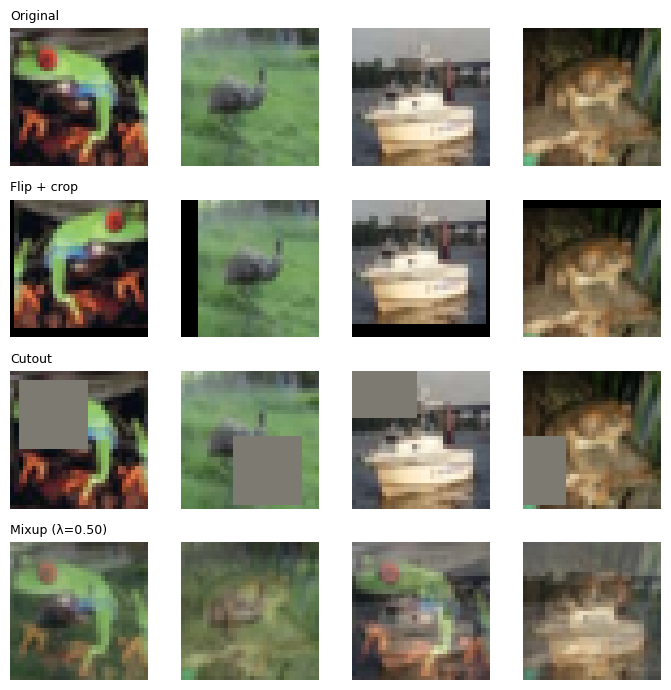

In [30]:
# 5k training images (first 5000 of the shuffled 45k train indices)
small_idx = train_idx[:5000]

flipcrop_tf = transforms.Compose([transforms.RandomCrop(32, padding=4),
                                  transforms.RandomHorizontalFlip(),
                                  transforms.ToTensor(), normalize])
cutout_tf = transforms.Compose([transforms.ToTensor(), normalize, Cutout(16)])
all_aug_tf = transforms.Compose([transforms.RandomCrop(32, padding=4),
                                 transforms.RandomHorizontalFlip(),
                                 transforms.ToTensor(), normalize, Cutout(16)])

def small_train_set(tf):
    ds = torchvision.datasets.CIFAR10(root="./data", train=True, download=False, transform=tf)
    return Subset(ds, small_idx)

# Clean (no augmentation) copy of the 5k images, used to measure train accuracy
small_train_clean_loader = DataLoader(Subset(full_train, small_idx), batch_size=256,
                                      shuffle=False, num_workers=2)

# Show what the augmentations do (same 4 images)
vis_x = torch.stack([full_train[i][0] for i in small_idx[:4]])
set_seed(SEED)
vis_flipcrop = torch.stack([small_train_set(flipcrop_tf)[i][0] for i in range(4)])
vis_cutout = torch.stack([small_train_set(cutout_tf)[i][0] for i in range(4)])
vis_mixup, _, _, vis_lam = mixup_batch(vis_x, torch.zeros(4, dtype=torch.long))

m_ = torch.tensor(mean).view(3, 1, 1); s_ = torch.tensor(std).view(3, 1, 1)
fig, ax = plt.subplots(4, 4, figsize=(7, 7))
for r, (title, imgs) in enumerate([("Original", vis_x), ("Flip + crop", vis_flipcrop),
                                   ("Cutout", vis_cutout), (f"Mixup (λ={vis_lam:.2f})", vis_mixup)]):
    for c in range(4):
        ax[r, c].imshow((imgs[c] * s_ + m_).permute(1, 2, 0).clamp(0, 1).numpy())
        ax[r, c].axis("off")
    ax[r, 0].set_title(title, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

In [31]:
def train_regularized(cfg, epochs=40, lr=0.01):
    set_seed(SEED)
    model = SmallCNNBN(dropout=cfg.get("dropout", 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                          weight_decay=cfg.get("wd", 0.0))
    train_ds = small_train_set(cfg.get("tf", base_transform))
    train_loader, val_loader = get_loaders(train_ds, val_set, batch_size=128)

    hist = {"train_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        total_loss, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            if cfg.get("mixup", False):
                x, y_a, y_b, lam = mixup_batch(x, y, alpha=1.0)
                out = model(x)
                loss = lam * F.cross_entropy(out, y_a) + (1 - lam) * F.cross_entropy(out, y_b)
            else:
                out = model(x)
                loss = F.cross_entropy(out, y)
            loss.backward()
            opt.step()
            total_loss += loss.item() * x.shape[0]
            n += x.shape[0]

        _, train_acc = evaluate_net(model, small_train_clean_loader)   # clean train images
        _, val_acc = evaluate_net(model, val_loader)
        hist["train_loss"].append(total_loss / n)
        hist["train_acc"].append(train_acc)
        hist["val_acc"].append(val_acc)
    return hist


reg_configs = {
    "Baseline":     {},
    "Weight decay": {"wd": 5e-4},
    "Dropout":      {"dropout": 0.5},
    "Flip + crop":  {"tf": flipcrop_tf},
    "Cutout":       {"tf": cutout_tf},
    "Mixup":        {"mixup": True},
    "All combined": {"wd": 5e-4, "dropout": 0.5, "tf": all_aug_tf, "mixup": True},
}
EPOCHS_REG = 40

reg_results = {}
start = time.time()
for name, cfg in reg_configs.items():
    reg_results[name] = train_regularized(cfg, epochs=EPOCHS_REG)
    h = reg_results[name]
    print(f"{name:13s} | train acc {h['train_acc'][-1]:.4f} | val acc {h['val_acc'][-1]:.4f}")
print(f"Total time: {(time.time() - start) / 60:.1f} min")

Baseline      | train acc 1.0000 | val acc 0.6478
Weight decay  | train acc 1.0000 | val acc 0.6514
Dropout       | train acc 0.8294 | val acc 0.6358
Flip + crop   | train acc 0.8068 | val acc 0.6656
Cutout        | train acc 0.9694 | val acc 0.6180
Mixup         | train acc 0.9820 | val acc 0.6080
All combined  | train acc 0.5446 | val acc 0.4998
Total time: 18.0 min


**Training Setup**

- Training uses only 5,000 images. Validation uses the full 5,000-image validation set.
- All runs use SGD with momentum 0.9, learning rate 0.01, batch size 128, and 40 epochs. Momentum at lr = 0.01 gave the best result in Task 2(c).
- All runs start from the same initial weights (same seed). Only the regularization changes.
- Train accuracy is measured on the **clean** 5k training images, without augmentation or mixup, in evaluation mode. So train and validation accuracy are measured in the same way, and the gap is a fair measure of overfitting.

In [32]:
rows = []
for name, h in reg_results.items():
    tr, va = h["train_acc"][-1], h["val_acc"][-1]
    rows.append({"Method": name,
                 "Train acc (%)": round(100 * tr, 2),
                 "Val acc (%)": round(100 * va, 2),
                 "Gap (%)": round(100 * (tr - va), 2),
                 "Best val acc (%)": round(100 * max(h["val_acc"]), 2)})
reg_table = pd.DataFrame(rows)
reg_table

,Method,Train acc (%),Val acc (%),Gap (%),Best val acc (%)
0,Baseline,100.00,64.78,35.22,64.94
1,Weight decay,100.00,65.14,34.86,65.32
2,Dropout,82.94,63.58,19.36,65.36
3,Flip + crop,80.68,66.56,14.12,67.86
4,Cutout,96.94,61.80,35.14,63.60
5,Mixup,98.20,60.80,37.40,63.26
6,All combined,54.46,49.98,4.48,51.04


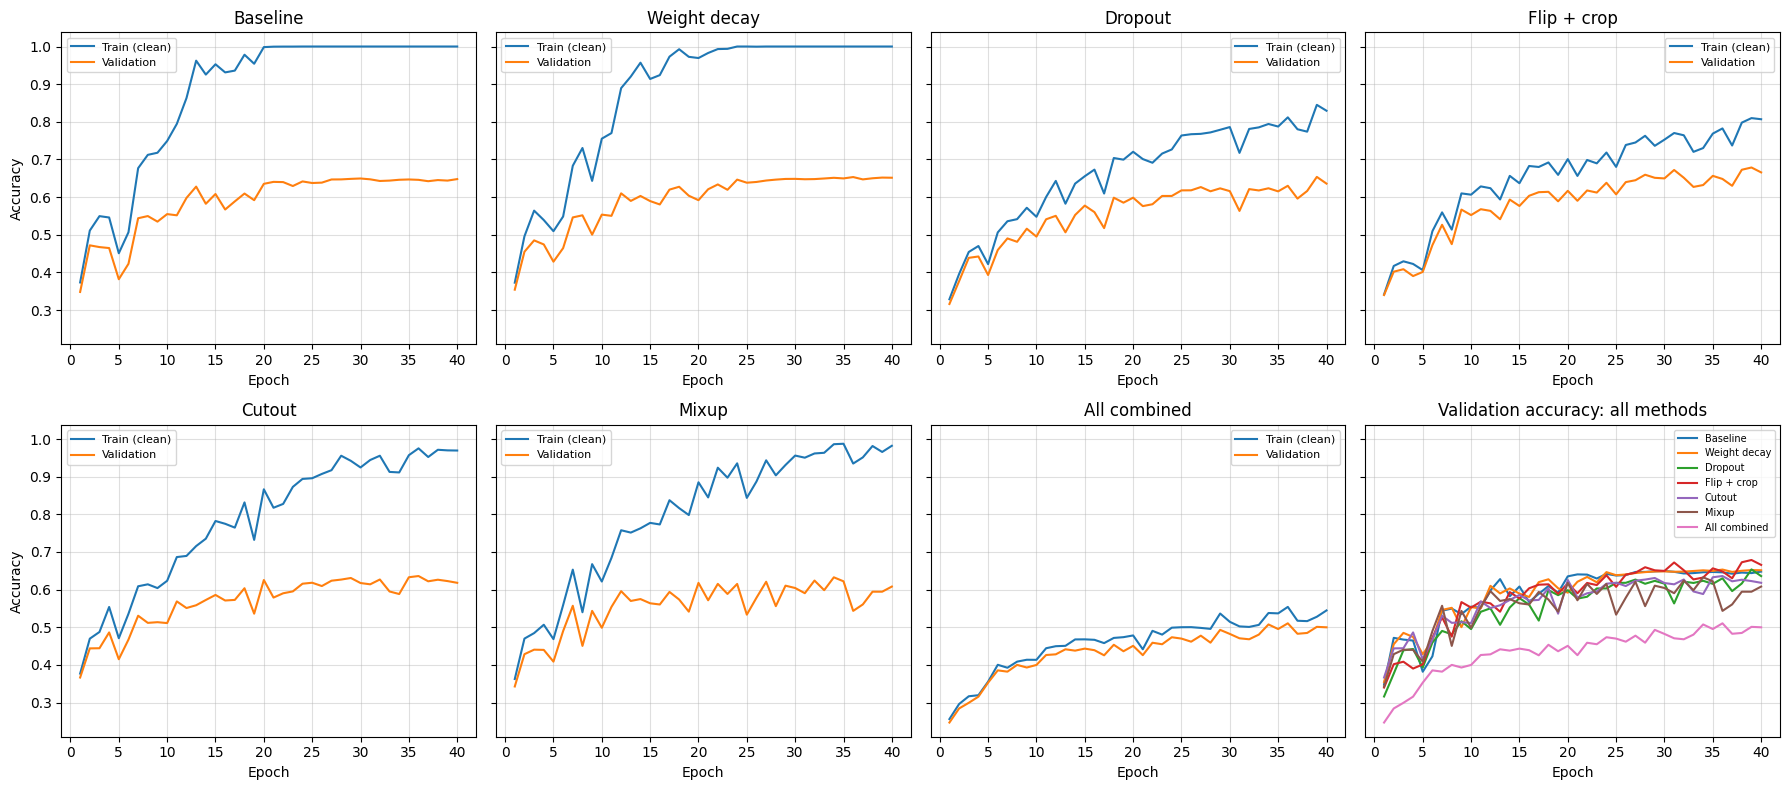

In [33]:
ep = range(1, EPOCHS_REG + 1)
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, (name, h) in enumerate(reg_results.items()):
    axes[i].plot(ep, h["train_acc"], label="Train (clean)")
    axes[i].plot(ep, h["val_acc"], label="Validation")
    axes[i].set_title(name)
    axes[i].set_xlabel("Epoch")
    axes[i].grid(True, alpha=0.4)
    axes[i].legend(fontsize=8)
axes[0].set_ylabel("Accuracy")
axes[4].set_ylabel("Accuracy")

for name, h in reg_results.items():
    axes[7].plot(ep, h["val_acc"], label=name)
axes[7].set_title("Validation accuracy: all methods")
axes[7].set_xlabel("Epoch")
axes[7].grid(True, alpha=0.4)
axes[7].legend(fontsize=7)

plt.tight_layout()
plt.show()

**Augmentation Examples**

- **Flip + crop:** some images are mirrored. Black borders appear where the 4-pixel padding is cropped in, so the object is slightly shifted.
- **Cutout:** a 16×16 square is replaced with the mean colour (grey). Near the edge, only part of the square is inside the image.
- **Mixup:** with λ = 0.5, each image is an equal blend of two images, for example the frog and the boat. The label is mixed in the same ratio.
- So all three augmentations work as intended.

**Interpretation**

**Baseline: strong overfitting**
- With only 5,000 training images, the model reaches 100% train accuracy by epoch 20, but the validation accuracy stays at about 65%.
- The gap is 35%. The model memorizes the training images.
- After train accuracy reaches 100%, the training loss is almost zero. So there is little gradient left, and the validation accuracy stays flat.

**Weight decay: almost no effect**
- The results are very close to the baseline (val 65.1%, gap 34.9%).
- $\lambda = 5 \times 10^{-4}$ is small for 40 epochs. Also, batch norm removes the effect of the weight scale in the conv layers, so shrinking these weights changes little. A larger $\lambda$ or longer training may be needed.

**Dropout: smaller gap**
- The gap falls to 19.4%. Dropout stops the FC layers from depending on single units, so memorizing is harder.
- The final val accuracy (63.6%) is similar to the baseline, but the best is 65.4%. Train accuracy is still rising at epoch 40, so more epochs would likely help.

**Flip + crop: best result**
- It gives the highest validation accuracy: 66.6% final and 67.9% best. The gap falls to 14.1%.
- Flipped and shifted images are still realistic images of the same class. So the model effectively sees more varied training data, without changing the labels.
- Train accuracy is still rising at epoch 40, so longer training could improve it further.

**Cutout: did not help here**
- The gap stays at 35%, and the val accuracy is lower (61.8%).
- The model still memorizes the clean training images (train 96.9%). Hiding a 16×16 square removes up to a quarter of a 32×32 image. With only 5k images and 40 epochs, this mostly makes learning harder, without stopping memorization.

**Mixup: did not help here**
- It has the largest gap (37.4%) and a lower val accuracy (60.8%). The validation curve is also very noisy.
- With $\lambda \sim \text{Beta}(1, 1)$, the mixing is strong. The model still learns to fit the clean images (train 98.2%). Mixup usually needs longer training to show its benefit.

**All combined: too much regularization**
- It has the smallest gap (4.5%), but also the lowest accuracy: train 54.5% and val 50.0%.
- The model now **underfits**. It cannot even fit the training data well. With all five methods together, the small CNN cannot learn enough in 40 epochs. The curves are still slowly rising.

**Summary**
- A small gap does not always mean better validation accuracy. The aim is a good balance between fitting the data and avoiding overfitting.
- In this setup, simple flip + crop gave the best validation accuracy.
- The strength of each regularization method (λ, dropout rate, cutout size, mixup α) and the training length must be tuned together. A combination that is too strong makes the model underfit.

### (b) Plain vs Residual Networks of Depth 6n + 2 (8, 20, 56)

In [34]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.residual = residual
        self.downsample = (stride != 1 or cin != cout)
        self.extra_ch = cout - cin

    def shortcut(self, x):
        if self.downsample:
            x = x[:, :, ::2, ::2]                                # halve H and W
            p = self.extra_ch // 2
            x = F.pad(x, (0, 0, 0, 0, p, self.extra_ch - p))     # zero-pad extra channels
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)                         # F(x) + x
        return F.relu(out)


class CifarNet(nn.Module):
    def __init__(self, depth, residual):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6                                     # blocks per stage
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(16), nn.ReLU())
        layers, cin = [], 16
        for stage, cout in enumerate([16, 32, 64]):
            for b in range(n):
                stride = 2 if (stage > 0 and b == 0) else 1      # first block of stage 2, 3 halves size
                layers.append(BasicBlock(cin, cout, stride, residual))
                cin = cout
        self.stages = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)                      # global average pooling
        self.fc = nn.Linear(64, 10)

        for m in self.modules():                                 # Kaiming initialization
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            if isinstance(m, nn.Linear):
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stages(self.stem(x))
        return self.fc(torch.flatten(self.pool(x), 1))


for depth in [8, 20, 56]:
    p_plain = sum(p.numel() for p in CifarNet(depth, residual=False).parameters())
    p_res = sum(p.numel() for p in CifarNet(depth, residual=True).parameters())
    print(f"Depth {depth:2d} (n = {(depth-2)//6}) | plain params {p_plain:,} | residual params {p_res:,}")

Depth  8 (n = 1) | plain params 75,290 | residual params 75,290
Depth 20 (n = 3) | plain params 269,722 | residual params 269,722
Depth 56 (n = 9) | plain params 853,018 | residual params 853,018


**Network Design**

- **Depth $6n + 2$:** 1 stem conv + 3 stages × $n$ blocks × 2 convs + 1 FC layer.
  - $n = 1$ → 8 layers, $n = 3$ → 20 layers, $n = 9$ → 56 layers.
- **Stem:** Conv 3×3 (16 channels) → BatchNorm → ReLU.
- **Three stages** with 16, 32, and 64 channels. The feature map size is 32×32, then 16×16, then 8×8.
  The first block of stages 2 and 3 uses stride 2. This halves the size and doubles the channels.
- **Block:** Conv 3×3 → BN → ReLU → Conv 3×3 → BN → (+ shortcut) → ReLU.
- **Head:** global average pooling (64 × 8 × 8 → 64) and one FC layer to 10 classes.
- **Kaiming initialization** is used for all conv and FC weights.

**The only difference is the shortcut:**
- **Plain block:** output $= \text{ReLU}(F(x))$
- **Residual block:** output $= \text{ReLU}(F(x) + x)$
- When the size changes, the shortcut takes every second pixel and fills the extra channels with zeros. This shortcut has **no parameters**.
- So the plain and residual networks of the same depth have exactly the same number of parameters (see the output above).

In [35]:
DEPTHS = [8, 20, 56]
EPOCHS_RES = 20

res_results = {}
start_all = time.time()
for residual in [False, True]:
    for depth in DEPTHS:
        name = f"{'ResNet' if residual else 'Plain'}-{depth}"
        set_seed(SEED)
        model = CifarNet(depth, residual).to(device)
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
        train_loader, val_loader = get_loaders(batch_size=128)
        t0 = time.time()
        hist = train_net(model, opt, train_loader, val_loader, epochs=EPOCHS_RES)
        hist["time_min"] = (time.time() - t0) / 60
        res_results[name] = hist
        print(f"{name:10s} | final train loss {hist['train_loss'][-1]:.4f} "
              f"| final train acc {hist['train_acc'][-1]:.4f} "
              f"| best val acc {max(hist['val_acc']):.4f} | {hist['time_min']:.1f} min")
print(f"Total time: {(time.time() - start_all) / 60:.1f} min")

Plain-8    | final train loss 0.3189 | final train acc 0.8881 | best val acc 0.7810 | 4.5 min
Plain-20   | final train loss 0.3079 | final train acc 0.8932 | best val acc 0.7886 | 5.5 min
Plain-56   | final train loss 1.1080 | final train acc 0.6091 | best val acc 0.5194 | 11.7 min
ResNet-8   | final train loss 0.3473 | final train acc 0.8780 | best val acc 0.7614 | 4.6 min
ResNet-20  | final train loss 0.1925 | final train acc 0.9318 | best val acc 0.7914 | 5.6 min
ResNet-56  | final train loss 0.2329 | final train acc 0.9173 | best val acc 0.7448 | 12.2 min
Total time: 44.0 min


**Training Setup**

- All six networks are trained on the full 45k training set, without data augmentation, for 20 epochs.
- Optimizer: SGD with momentum 0.9, learning rate 0.1, weight decay $10^{-4}$, and batch size 128. These are the settings used in the original ResNet paper for CIFAR-10.
- All networks start from the same seed.
- The training loss is the mean cross-entropy over each epoch.

In [36]:
rows = []
for name, h in res_results.items():
    rows.append({"Network": name,
                 "Final train loss": round(h["train_loss"][-1], 4),
                 "Final train acc (%)": round(100 * h["train_acc"][-1], 2),
                 "Best val acc (%)": round(100 * max(h["val_acc"]), 2),
                 "Time (min)": round(h["time_min"], 1)})
pd.DataFrame(rows)

,Network,Final train loss,Final train acc (%),Best val acc (%),Time (min)
0,Plain-8,0.3189,88.81,78.10,4.5
1,Plain-20,0.3079,89.32,78.86,5.5
2,Plain-56,1.1080,60.91,51.94,11.7
3,ResNet-8,0.3473,87.80,76.14,4.6
4,ResNet-20,0.1925,93.18,79.14,5.6
5,ResNet-56,0.2329,91.73,74.48,12.2


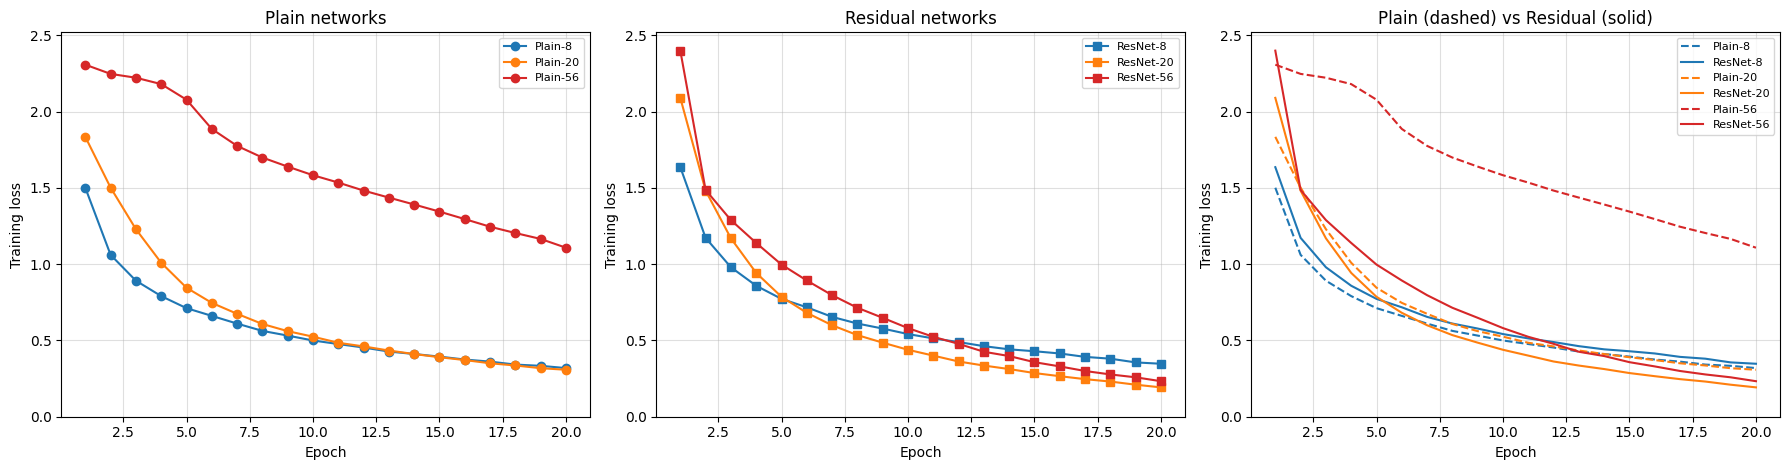

In [37]:
ep = range(1, EPOCHS_RES + 1)
colors = {8: "tab:blue", 20: "tab:orange", 56: "tab:red"}

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for d in DEPTHS:
    ax[0].plot(ep, res_results[f"Plain-{d}"]["train_loss"], "o-", color=colors[d], label=f"Plain-{d}")
    ax[1].plot(ep, res_results[f"ResNet-{d}"]["train_loss"], "s-", color=colors[d], label=f"ResNet-{d}")
    ax[2].plot(ep, res_results[f"Plain-{d}"]["train_loss"], "--", color=colors[d], label=f"Plain-{d}")
    ax[2].plot(ep, res_results[f"ResNet-{d}"]["train_loss"], "-", color=colors[d], label=f"ResNet-{d}")

titles = ["Plain networks", "Residual networks", "Plain (dashed) vs Residual (solid)"]
ymax = max(max(h["train_loss"]) for h in res_results.values())
for a, t in zip(ax, titles):
    a.set_title(t)
    a.set_xlabel("Epoch")
    a.set_ylabel("Training loss")
    a.set_ylim(0, ymax * 1.05)
    a.grid(True, alpha=0.4)
    a.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Explanation**

**Same size, only the shortcut differs**
- Plain and residual networks of the same depth have exactly the same number of parameters: 75k, 270k, and 853k. So any difference in training comes only from the shortcut.

**Plain networks: deeper is worse (degradation)**
- Plain-8 and Plain-20 reach almost the same training loss (0.32 and 0.31). Adding 12 layers gives no benefit.
- Plain-56 is much worse. Its loss stays near 2.30 (≈ log 10, random guessing) for the first 4 epochs. It ends at 1.11, with only 60.9% train accuracy.
- This is not overfitting. Plain-56 has a higher **training** loss than the shallower networks, so it is underfitting.
- A 56-layer network could, in theory, copy a 20-layer network by setting its extra layers to identity. But the plain network cannot learn this. Deeper plain networks are harder to optimize, even with batch norm and Kaiming initialization.

**Residual networks: deeper trains well**
- All three residual networks train well. At epoch 20, ResNet-20 (0.19) and ResNet-56 (0.23) both reach lower loss than ResNet-8 (0.35).
- ResNet-56 starts slower, but its loss falls steadily, and its curve is still dropping quickly at epoch 20. With more epochs, it would likely reach the lowest loss.

**Plain vs residual at the same depth**
- **Depth 8:** almost no difference (0.32 vs 0.35). A shallow network is easy to train without shortcuts.
- **Depth 20:** the residual network is clearly better (0.19 vs 0.31).
- **Depth 56:** the difference is very large (0.23 vs 1.11). The deeper the network, the more the shortcut helps.

**Why the shortcut helps**
- A residual block computes $F(x) + x$. If the conv weights go to zero, the block becomes the identity. So extra layers can easily "do nothing", and a deep network is never worse than a shallower one.
- In the backward pass, the addition passes the gradient straight back through the shortcut, with local gradient 1. So the gradient reaches the early layers without shrinking through many conv layers. This is the same vanishing gradient issue seen with sigmoid in Task 1(d).

**Validation accuracy**
- ResNet-20 has the best validation accuracy (79.1%), and Plain-56 the worst (51.9%).
- ResNet-56 fits the training data well (91.7%), but its validation accuracy is lower (74.5%). With no data augmentation, the larger network starts to overfit.

**Summary**
- Without shortcuts, making a network deeper can make it **harder to train**. Plain-56 is far worse than Plain-20.
- With shortcuts, deep networks train easily. This is why residual connections make very deep CNNs possible.

# Task 4: Best CNN (≤ 500k Parameters, ≤ 20 Epochs)

In [38]:
class SmallResNet(nn.Module):
    def __init__(self, blocks=(2, 2, 1), widths=(32, 64, 128), residual=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU())
        layers, cin = [], widths[0]
        for stage, (nb, cout) in enumerate(zip(blocks, widths)):
            for b in range(nb):
                stride = 2 if (stage > 0 and b == 0) else 1
                layers.append(BasicBlock(cin, cout, stride, residual))   # block from Task 3(b)
                cin = cout
        self.stages = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], 10)

        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            if isinstance(m, nn.Linear):
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stages(self.stem(x))
        return self.fc(torch.flatten(self.pool(x), 1))


n_params_final = sum(p.numel() for p in SmallResNet().parameters())
print(f"SmallResNet parameters: {n_params_final:,}  (limit 500,000)")
assert n_params_final <= 500_000

SmallResNet parameters: 390,570  (limit 500,000)


**Network Design**

- The design is based on the residual network from Task 3(b), but **wider**: 32, 64, and 128 channels instead of 16, 32, and 64.
- Wider layers give more features per layer. Within a 500k limit, this is a better use of parameters than many thin layers. Shallow residual networks also train faster in 20 epochs.
- **Blocks per stage:** 2, 2, 1. So there are 1 stem conv + 10 block convs + 1 FC = 12 layers.
  Stage 3 has 128 channels, so each of its convs is costly. Only one block is used there to stay under 500k.
- Same parts as before: BatchNorm, ReLU, a parameter-free shortcut, global average pooling, and Kaiming initialization.
- Total: about 390k parameters, which is below the 500k limit.

In [39]:
train_aug_full = Subset(torchvision.datasets.CIFAR10(root="./data", train=True, download=False,
                                                     transform=flipcrop_tf), train_idx)

def train_final(cfg, epochs=20):
    set_seed(SEED)
    model = SmallResNet(residual=cfg["residual"]).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9,
                          weight_decay=cfg["wd"])
    train_ds = train_aug_full if cfg["aug"] else train_set
    train_loader, val_loader = get_loaders(train_ds, val_set, batch_size=128)

    total_steps = epochs * len(train_loader)
    sched = (torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_steps)
             if cfg["cosine"] else None)

    hist = {"train_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        total_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = F.cross_entropy(out, y)
            loss.backward()
            opt.step()
            if sched is not None:
                sched.step()                          # update learning rate every iteration
            total_loss += loss.item() * x.shape[0]
            correct += (out.argmax(dim=1) == y).sum().item()
            n += x.shape[0]
        _, val_acc = evaluate_net(model, val_loader)
        hist["train_loss"].append(total_loss / n)
        hist["train_acc"].append(correct / n)
        hist["val_acc"].append(val_acc)
    hist["state"] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    return hist


final_cfg = {"residual": True, "aug": True, "wd": 5e-4, "cosine": True, "lr": 0.1}
ablation_cfgs = {
    "Final (all choices)":    final_cfg,
    "No shortcut (plain)":    {**final_cfg, "residual": False},
    "No augmentation":        {**final_cfg, "aug": False},
    "No weight decay":        {**final_cfg, "wd": 0.0},
    "Constant LR (no cosine)": {**final_cfg, "cosine": False},
}
EPOCHS_FINAL = 20

final_results = {}
start = time.time()
for name, cfg in ablation_cfgs.items():
    t0 = time.time()
    final_results[name] = train_final(cfg, epochs=EPOCHS_FINAL)
    h = final_results[name]
    print(f"{name:24s} | final val acc {h['val_acc'][-1]:.4f} | best val acc {max(h['val_acc']):.4f} "
          f"| final train acc {h['train_acc'][-1]:.4f} | {(time.time()-t0)/60:.1f} min")
print(f"Total time: {(time.time() - start) / 60:.1f} min")

Final (all choices)      | final val acc 0.8836 | best val acc 0.8842 | final train acc 0.9224 | 7.4 min
No shortcut (plain)      | final val acc 0.8812 | best val acc 0.8820 | final train acc 0.9241 | 7.2 min
No augmentation          | final val acc 0.8412 | best val acc 0.8432 | final train acc 0.9999 | 7.1 min
No weight decay          | final val acc 0.8634 | best val acc 0.8634 | final train acc 0.8925 | 7.3 min
Constant LR (no cosine)  | final val acc 0.7000 | best val acc 0.7706 | final train acc 0.8280 | 7.2 min
Total time: 36.1 min


**Training Setup and Ablation**

**Final training recipe**
- Data: full 45k training set with flip + crop augmentation. Flip + crop was the best method in Task 3(a).
- Optimizer: SGD with momentum 0.9, learning rate 0.1, weight decay $5 \times 10^{-4}$, and batch size 128. SGD with momentum was the least sensitive optimizer in Task 2(c).
- **Cosine learning rate schedule:** the learning rate starts at 0.1 and smoothly falls to 0 by the end of epoch 20:
  $\eta_t = \dfrac{\eta_0}{2}\left(1 + \cos\dfrac{\pi t}{T}\right)$, where $T$ is the total number of steps.
  Large steps at the start make fast progress. Small steps at the end let the model settle into a good minimum.
- 20 epochs, which is the maximum allowed.

**Ablation:** each run removes **one** design choice from the final recipe. Everything else stays the same, including the seed.
1. **Shortcut:** residual vs plain network
2. **Augmentation:** flip + crop vs none
3. **Weight decay:** $5 \times 10^{-4}$ vs 0
4. **Learning rate schedule:** cosine vs constant learning rate 0.1

**Tuning:** all decisions use the **validation** accuracy at the end of epoch 20. The run with the best final validation accuracy is chosen as the final model. Only that model is evaluated on the test set, once.

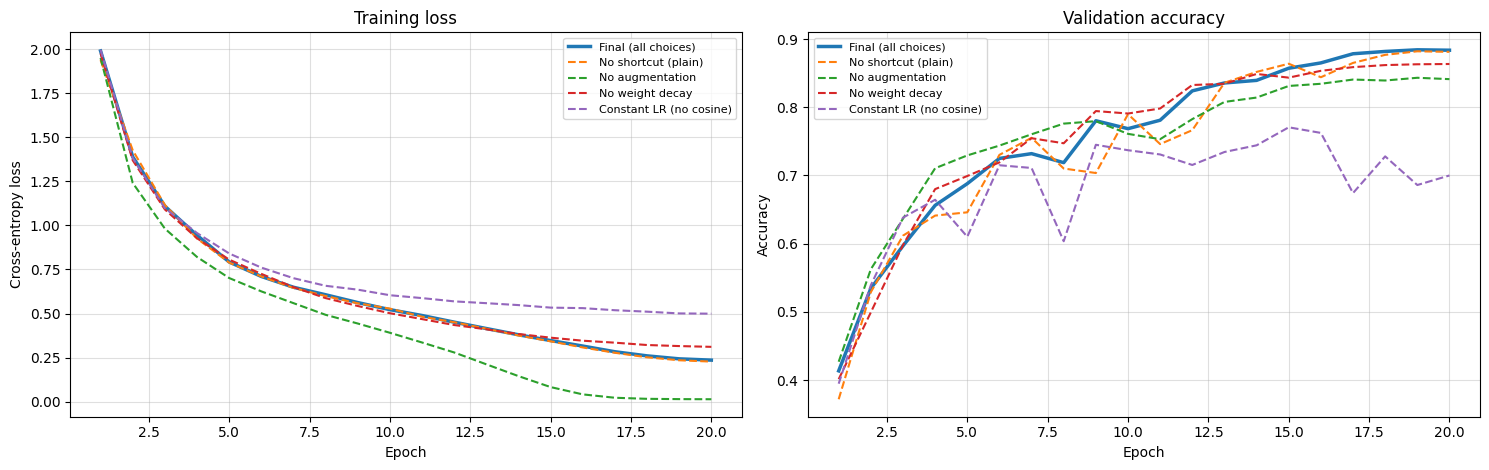

In [40]:
ep = range(1, EPOCHS_FINAL + 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for name, h in final_results.items():
    style = "-" if name.startswith("Final") else "--"
    lw = 2.5 if name.startswith("Final") else 1.5
    ax[0].plot(ep, h["train_loss"], style, linewidth=lw, label=name)
    ax[1].plot(ep, h["val_acc"], style, linewidth=lw, label=name)

ax[0].set_title("Training loss")
ax[0].set_ylabel("Cross-entropy loss")
ax[1].set_title("Validation accuracy")
ax[1].set_ylabel("Accuracy")
for a in ax:
    a.set_xlabel("Epoch")
    a.grid(True, alpha=0.4)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Final Model: Test Accuracy (Evaluated Once)**

In [41]:
# Choose the final model by validation accuracy only
best_run = max(final_results, key=lambda k: final_results[k]["val_acc"][-1])
print("Selected model (best final val acc):", best_run)

final_model = SmallResNet(residual=ablation_cfgs[best_run]["residual"]).to(device)
final_model.load_state_dict(final_results[best_run]["state"])

# Test set used here for the first and only time
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)
test_loss, test_acc = evaluate_net(final_model, test_loader)

print(f"Parameters:      {sum(p.numel() for p in final_model.parameters()):,}")
print(f"Epochs:          {EPOCHS_FINAL}")
print(f"Validation acc:  {100 * final_results[best_run]['val_acc'][-1]:.2f}%")
print(f"Test acc:        {100 * test_acc:.2f}%")

Selected model (best final val acc): Final (all choices)
Parameters:      390,570
Epochs:          20
Validation acc:  88.36%
Test acc:        88.32%


### Ablation Results

| Run | Final val acc (%) | Change vs final (%) |
|---|---|---|
| **Final (all choices)** | **88.36** | — |
| No shortcut (plain) | 88.12 | −0.24 |
| No augmentation | 84.12 | −4.24 |
| No weight decay | 86.34 | −2.02 |
| Constant LR (no cosine) | 70.00 | −18.36 |

The full recipe gives the best validation accuracy. Removing any one choice makes it worse. Ranked from largest to smallest effect:

**1. Cosine learning rate schedule (−18.4%)**
- With a constant learning rate of 0.1, the validation accuracy jumps up and down between 60% and 77% and ends at only 70.0%. The training loss stays near 0.50.
- The steps are too large for the model to settle into a good minimum.
- With the cosine schedule, the steps get smaller near the end. The loss keeps falling and the validation accuracy rises smoothly to 88.4%.
- In a short 20-epoch budget, the schedule is the most important choice.

**2. Data augmentation (−4.2%)**
- Without flip + crop, the model memorizes the training set: train accuracy 99.99%, training loss almost 0. The validation accuracy stops at 84.1%.
- The no-augmentation run learns faster in the first epochs (lower loss, higher val accuracy up to epoch 8). But with augmentation, the model keeps improving later and ends much higher.
- The train–val gap falls from 15.9% to 3.9% with augmentation.

**3. Weight decay (−2.0%)**
- Without weight decay, the validation accuracy is 86.3%. The train accuracy is also lower (89.3% vs 92.2%), and the training loss is higher near the end.
- So weight decay here helps optimization, not only overfitting. With batch norm, the output does not depend on the weight scale. Without weight decay, the weights grow, and the effective step size becomes smaller. So the model learns more slowly near the end.

**4. Shortcut (−0.2%)**
- The plain network is almost as good (88.1% vs 88.4%). This small difference is likely within run-to-run noise.
- This network has only 12 layers. In Task 3(b), shortcuts made little difference at shallow depth and only mattered for deep networks. The same is seen here.
- The shortcut is kept because it is free (no extra parameters) and gave slightly higher accuracy.

**Final Model**

- **Network:** 12-layer residual CNN, widths 32/64/128, **390,570 parameters** (limit 500k).
- **Training:** 20 epochs, SGD with momentum 0.9, learning rate 0.1 with cosine schedule, weight decay $5 \times 10^{-4}$, flip + crop augmentation.
- **Validation accuracy:** 88.36%
- **Test accuracy (evaluated once): 88.32%**

The test accuracy is almost the same as the validation accuracy (difference 0.04%). This shows the design choices did not overfit to the validation set, so the validation accuracy was a reliable guide for tuning.